# 📊 01 — Exploratory Data Analysis (EDA)

**Dataset:** Rossmann Store Sales  
**Goal:** Understand data shape, quality, seasonality, and promo/holiday effects before modelling.

Work through each section **in order**. Every section has:
- A 💡 **Hint** block — *what* to look for and *why* it matters
- A code stub — fill in the `# TODO` lines yourself

---

## 0 — Setup

> 💡 **Hint:** Import libraries and load the config up front.
> Every path and column name should come from `cfg` — never hardcode `'sales'` or `'data/processed'` inline.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

sys.path.insert(0, '..')   # makes src/ importable from notebooks/
from src.utils.io import load_config

cfg = load_config('../configs/config.yaml')

# TODO: print(cfg)  -- understand every key before using it

plt.rcParams['figure.figsize'] = (14, 4)
sns.set_theme(style='whitegrid')

---
## 1 — Load Data

> 💡 **Hint:** Load `long_format.parquet` (output of `src/data/load_data.py`).
> This is the merged + cleaned file — NOT the raw CSVs.
> - Make sure the `date` column is `datetime64`, not a string.
> - Print `.dtypes` and `.head()` immediately — this is your first sanity check.


In [2]:
date_col = cfg['date_col']     # 'date'
target   = cfg['target_col']   # 'sales'
id_cols  = cfg['id_cols']      # ['store_id', 'item_id']

# TODO: read '../data/processed/long_format.parquet' into df
df = pd.read_parquet('../data/processed/long_format.parquet')

# TODO: parse the date column to datetime64
df[date_col] = pd.to_datetime(df[date_col])

# TODO: print df.shape, df.dtypes, and df.head()
print("shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
df.head()

shape: (1017209, 19)

Dtypes:
 store_id                              int64
DayOfWeek                             int64
date                         datetime64[us]
sales                                 int64
Customers                             int64
Open                                  int64
promo                                 int64
state_holiday                           str
school_holiday                        int64
StoreType                               str
Assortment                              str
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                           str
item_id                                 str
dtype: object


,store_id,DayOfWeek,date,sales,Customers,Open,promo,state_holiday,school_holiday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,item_id
0,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,1
1,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,1
2,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,1
3,1,5,2013-01-04,4486,619,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,1
4,1,6,2013-01-05,4997,635,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,1


---
## 2 — Dataset Overview

> 💡 **Hint:** Before any plotting, answer these questions:
> 1. How many unique stores? Items? (For Rossmann, `item_id == store_id`.)
> 2. What is the full date range? Frequency (daily)?
> 3. Does `len(df) == n_stores × n_days`? If not → **missing dates**.
> 4. `df.groupby('store_id')['date'].count()` — spot stores with fewer rows than expected.
>
> ⚠️ Missing dates break lag/rolling features if not handled before feature engineering.


In [3]:
# TODO: print number of unique stores and unique items
n_stores =

# TODO: print df[date_col].min() and df[date_col].max()

# TODO: compute expected_rows = n_stores * n_days, compare to len(df)

# TODO: df.groupby('store_id')['date'].count().sort_values()  -- spot short stores

---
## 3 — Missing Values

> 💡 **Hint:** Two types of missingness to check:
> 1. **Explicit NaNs** — `df.isnull().sum()` per column.
> 2. **Implicit gaps** — dates that simply don't exist for a given store in the dataframe.
>
> For implicit gaps: pick store_id=1, build a full `pd.date_range`, find which dates are absent.
>
> **Plot idea:** Bar chart of null% per column (much faster than a heatmap on 1M+ rows).


In [4]:
# TODO: compute null % per column
null_pct = ...
# TODO: plot null_pct as a horizontal bar chart

# TODO: for store_id=1, build pd.date_range from min to max date,
#       find which dates are in the range but NOT in df for that store

---
## 4 — Sales Distribution

> 💡 **Hint:** Retail sales distributions are almost always **right-skewed** with a spike at zero (closed stores).
> - Histogram of raw `sales` — does it look log-normal?
> - Histogram of `log1p(sales)` — does it become bell-shaped?
> - How many zero-sales rows? Are those the Sundays (closed stores)?
> - Compare `df[df.sales > 0].sales.describe()` vs `df.sales.describe()`.
>
> **Why this matters:** LightGBM uses a Tweedie objective (see `config.yaml`) — chosen because of this zero-inflated skew.


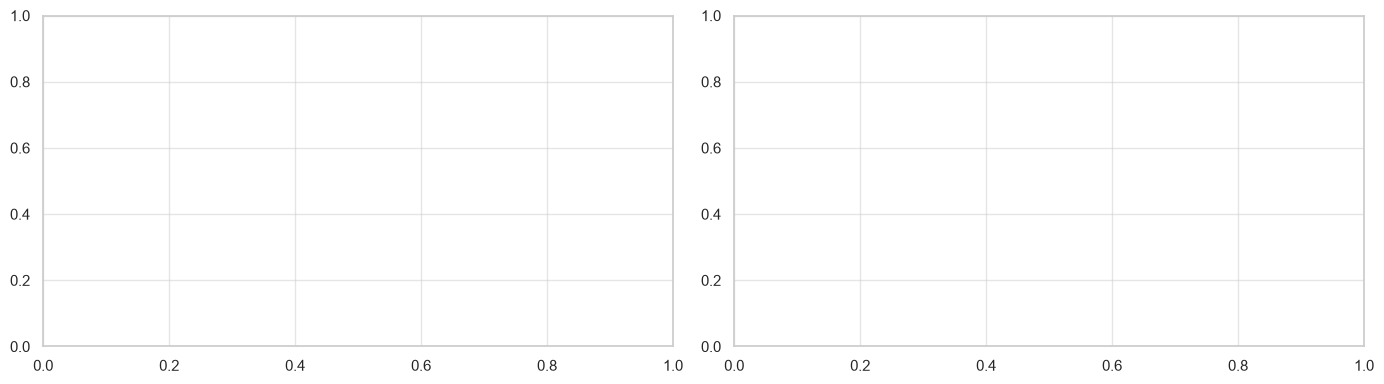

In [5]:
# TODO: print df['sales'].describe()

# TODO: print count and % of zero-sales rows

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# TODO: axes[0] -- histogram of raw sales
# TODO: axes[1] -- histogram of np.log1p(df['sales'])
# Label each subplot with a title
plt.tight_layout()

---
## 5 — Aggregate Sales Trend Over Time

> 💡 **Hint:** Sum all stores to get total daily sales and plot the full date range.
> - Is there an upward or downward multi-year trend?
> - Can you see Christmas spikes or summer dips visually?
> - Overlay a **30-day rolling mean** on top to reveal the smooth trend beneath daily noise.
>
> `daily_sales.rolling(30).mean()` plotted as a thick line on top of the raw series is a standard trick.


In [6]:
# TODO: daily_sales = df.groupby(date_col)[target].sum()
daily_sales = ...

# TODO: plot daily_sales as a thin line
# TODO: overlay daily_sales.rolling(30).mean() as a thick line in a different color
# Add axis labels and legend

---
## 6 — Seasonality Patterns

> 💡 **Hint:** Check three calendar levels:
>
> **6a — Day-of-week** (`df.groupby('day_of_week')[target].mean()`)
> - Rossmann is closed Sundays → expect near-zero for `day_of_week == 6`.
> - Use a bar chart.
>
> **6b — Month** (`df.groupby('month')[target].mean()`)
> - Is December the peak? Which month is the trough?
>
> **6c — Year-over-year** — group by `year + month`, plot one line per year on the same axes.
> - Are patterns stable across years, or drifting upward?


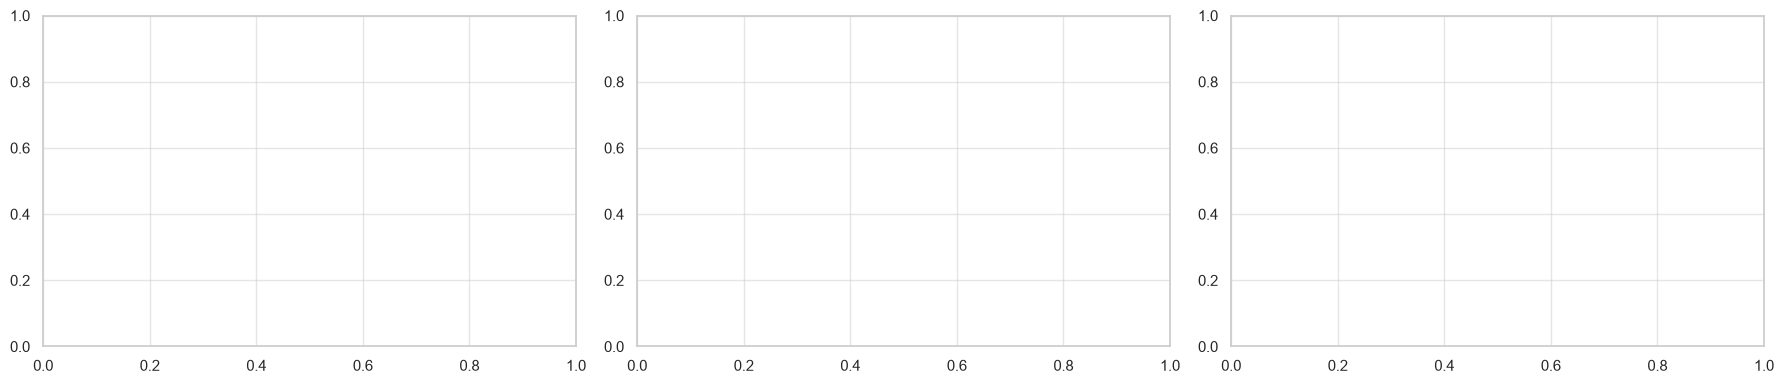

In [7]:
# Calendar columns may not be in long_format.parquet -- derive them here if needed:
# TODO: df['day_of_week'] = df[date_col].dt.dayofweek
# TODO: df['month']       = df[date_col].dt.month
# TODO: df['year']        = df[date_col].dt.year

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# TODO: 6a -- barplot of mean sales by day_of_week on axes[0]
#            map 0-6 -> ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

# TODO: 6b -- barplot of mean sales by month on axes[1]

# TODO: 6c -- line plot, one line per year, x=month, y=mean sales, on axes[2]

plt.tight_layout()

---
## 7 — Store-level Variation

> 💡 **Hint:** Sales can vary by 10× across stores. The global LightGBM model must handle this via `store_id` as a categorical feature.
> - Rank stores by mean daily sales — which 5 are highest? Lowest?
> - Horizontal bar chart of top 20 stores by mean sales.
> - Time series for the top 3 and bottom 3 stores — do trends move together or independently?
>
> **Insight:** Stores whose trends are uncorrelated benefit most from a global model that shares patterns cross-series.


In [8]:
# TODO: store_stats = df.groupby('store_id')[target].agg(['mean','std','sum'])
store_stats = ...

# TODO: print top 5 and bottom 5 stores by mean

# TODO: horizontal bar chart -- top 20 stores by mean sales

# TODO: plot daily sales time series for top 3 and bottom 3 stores (subplots)

---
## 8 — Promo Effect

> 💡 **Hint:** `promo` is binary (0/1). Quantify the sales lift:
> - `df.groupby('promo')[target].mean()` — what is the average % lift?
> - Violin or box plot of sales split by promo (non-zero rows only to exclude closed days).
> - Compute per-store promo lift and plot a histogram — is the lift consistent or variable by store?
>
> **Key question:** Are there stores where promo *reduces* sales? That would be a data quality flag.


In [9]:
# TODO: print mean sales with and without promo, compute % lift

# TODO: sns.violinplot(x='promo', y='sales', data=df[df.sales > 0])

# TODO: per-store lift = (promo_mean - no_promo_mean) / no_promo_mean * 100
#       plot a histogram of these lift values across all stores

---
## 9 — Holiday Effect

> 💡 **Hint:** Rossmann has `state_holiday` (types: 0, a, b, c) and `school_holiday` (binary).
> - `df.groupby('state_holiday')[target].mean()` — do public holidays suppress or lift sales?
> - `df.groupby('school_holiday')[target].mean()` — is the effect different?
> - Plot daily sales for year 2014 only and add vertical lines at known holidays (e.g., Dec 25).
>
> **Why it matters:** Prophet uses holiday regressors (`config.yaml: holidays: true`) — your EDA tells you whether that is actually useful.


In [10]:
# TODO: df.groupby('state_holiday')[target].mean()

# TODO: df.groupby('school_holiday')[target].mean()

# TODO: filter daily_sales to 2014, plot as line
#       add plt.axvline(pd.Timestamp('2014-12-25'), color='red', label='Christmas')

---
## 10 — Feature Correlations

> 💡 **Hint:** Load `features.parquet` — it contains all lag and rolling columns from `build_features.py`.
> - Correlate every numeric feature with `sales` — which lag is strongest?
> - Expect `sales_lag_7` to rank highest (same weekday last week).
> - Heatmap of the lag/rolling sub-matrix to see inter-feature correlations too.
>
> ⚠️ `roll_mean_7` and `roll_mean_14` will be highly correlated with each other — **multicollinearity**.
> Harmless for tree models (LightGBM) but important to understand.


In [11]:
# TODO: feat_df = pd.read_parquet('../data/processed/features.parquet')
feat_df = ...

# TODO: corr_with_sales = feat_df.select_dtypes('number').corr()['sales']
#       print top 10 (positive and negative)

# TODO: heatmap -- filter columns starting with 'sales_lag' or 'sales_roll'
#       sns.heatmap(..., annot=True, fmt='.2f', cmap='coolwarm')

---
## 11 — Autocorrelation (ACF / PACF)

> 💡 **Hint:** ACF/PACF shows how much today's sales depends on past days — the foundation of why lag features work.
> - Pick store_id=1, plot ACF and PACF up to 60 lags.
> - Look for **spikes at lag 7, 14, 21** → weekly seasonality confirmed in the data.
> - Slow ACF decay → strong AR behaviour; sharp PACF cutoff → helps choose SARIMA order.
>
> Bars outside the blue shaded confidence band = statistically significant.


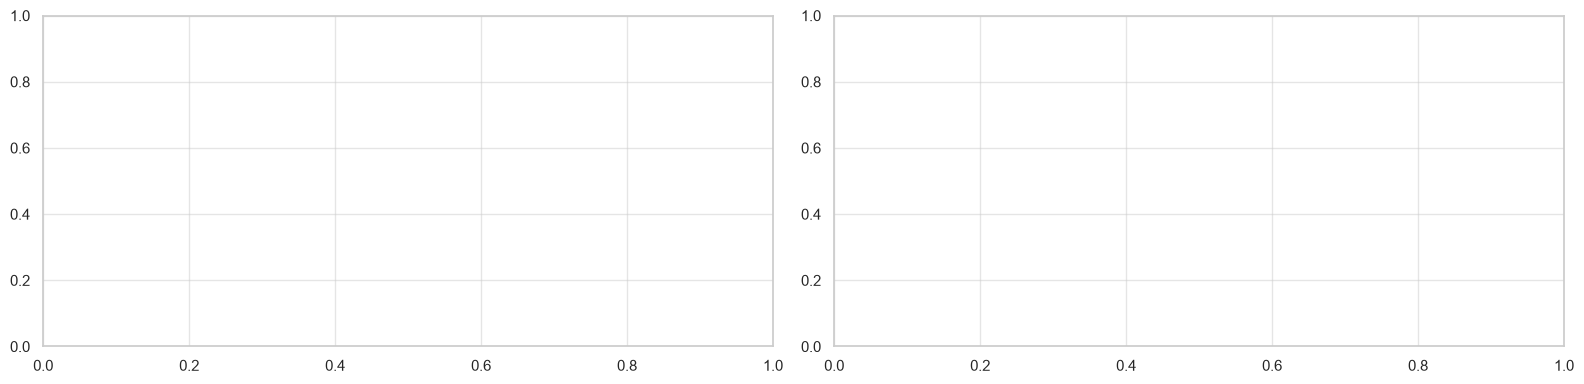

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# TODO: store1 = df[df['store_id']==1].set_index(date_col)['sales']
# Drop zeros (closed-store Sundays distort autocorrelation)
# store1 = store1[store1 > 0]
store1 = ...

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
# TODO: plot_acf(store1,  lags=60, ax=axes[0], title='ACF -- Store 1')
# TODO: plot_pacf(store1, lags=60, ax=axes[1], title='PACF -- Store 1')
plt.tight_layout()

---
## 12 — Time-Series Decomposition

> 💡 **Hint:** Decompose into **Trend + Seasonality + Residual** using `seasonal_decompose`.
> - Use `period=7` to target weekly seasonality.
> - Try `model='additive'` first. Switch to `'multiplicative'` if the seasonal swings grow with the level.
> - Inspect the **residual** panel — is it white noise (random) or still structured?
>
> **Rule of thumb:** Structured residuals = unexplained signal your features must capture.


In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose

# TODO: reuse store1 from section 11 (non-zero, datetime-indexed, daily freq)

# TODO: result = seasonal_decompose(store1, model='additive', period=7)

# TODO: result.plot()   -- inspect the four panels: observed, trend, seasonal, residual

---
## 13 — Outlier Detection

> 💡 **Hint:** Flag extreme values — but do NOT blindly remove them. A spike on Black Friday is real signal.
> - **Z-score per store:** `(sales - store_mean) / store_std`; flag `|z| > 3`.
> - **IQR method:** flag rows below Q1 - 1.5×IQR or above Q3 + 1.5×IQR.
> - For each flagged row, inspect: what date? `promo==1`? `state_holiday != 0`?
>
> A spike on a known promo day = real signal to keep. A spike on a random Tuesday = potential data error.


In [14]:
# TODO: df['z_score'] = df.groupby('store_id')['sales'].transform(
#           lambda x: (x - x.mean()) / x.std())

# TODO: outliers = df[df['z_score'].abs() > 3]
outliers = ...

# TODO: print outliers[[date_col, 'store_id', 'sales', 'promo', 'state_holiday']].sort_values('sales', ascending=False)

# TODO: for one outlier store, plot its full time series
#       and overlay outlier points as red dots

---
## 14 — EDA Summary  *(fill in after running all cells)*

> 💡 **Hint:** A complete EDA summary answers the questions below.
> Your findings here directly inform decisions in `02_baselines.ipynb` and `03_lightgbm.ipynb` — e.g., which baselines make sense, which features to prioritise, and whether to keep zeros in training.

| Question | Your Finding |
|:---------|:-------------|
| Data quality issues? | *(e.g., X% zero-sales rows — Sundays)* |
| Missing dates? | *(e.g., N stores have implicit gaps)* |
| Strongest seasonality? | *(e.g., weekly > monthly)* |
| Promo lift? | *(e.g., +N% on average)* |
| Holiday impact? | *(e.g., state holidays → -N%)* |
| Most correlated lag? | *(e.g., lag_7 at r = 0.XX)* |
| Outliers count and nature? | *(e.g., N rows, mostly December spikes)* |
| Watch out for in modelling? | *(your notes here)* |
